In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

pasta = Path(
    "/content/drive/MyDrive/DADOS-LANDSATRIO_RECORTADOS"
)

arquivos = sorted(pasta.glob("*.tif"))

print("Quantidade de arquivos:", len(arquivos))

for arquivo in arquivos:
    print(arquivo.name)

assert len(arquivos) == 18, "Esperados 18 arquivos GeoTIFF."

Quantidade de arquivos: 18
LST_2020_RIO.tif
LST_2021_RIO.tif
LST_2022_RIO.tif
LST_2023_RIO.tif
LST_2024_RIO.tif
LST_2025_RIO.tif
NDBI_2020_RIO.tif
NDBI_2021_RIO.tif
NDBI_2022_RIO.tif
NDBI_2023_RIO.tif
NDBI_2024_RIO.tif
NDBI_2025_RIO.tif
NDVI_2020_RIO.tif
NDVI_2021_RIO.tif
NDVI_2022_RIO.tif
NDVI_2023_RIO.tif
NDVI_2024_RIO.tif
NDVI_2025_RIO.tif


In [3]:
import numpy as np
import pandas as pd
import rasterio

resultados = []

for ano in range(2020, 2026):
    registro = {"Ano": ano}

    for variavel in ["LST", "NDVI", "NDBI"]:
        caminho = pasta / f"{variavel}_{ano}_RIO.tif"

        with rasterio.open(caminho) as src:
            dados = src.read(1, masked=True)
            valores = dados.compressed().astype(np.float64)

            valores = valores[np.isfinite(valores)]
            valores = valores[valores != -9999]

            total_validos = len(valores)

            if variavel in ["NDVI", "NDBI"]:
                fora_intervalo = np.count_nonzero(
                    (valores < -1) | (valores > 1)
                )
                valores = valores[
                    (valores >= -1) & (valores <= 1)
                ]
            else:
                fora_intervalo = 0

            registro[f"{variavel}_pixels_validos"] = len(valores)
            registro[f"{variavel}_pixels_fora_intervalo"] = int(
                fora_intervalo
            )

            if len(valores) > 0:
                registro[f"{variavel}_media"] = np.mean(valores)
                registro[f"{variavel}_min"] = np.min(valores)
                registro[f"{variavel}_max"] = np.max(valores)
                registro[f"{variavel}_desvio"] = np.std(valores)
                registro[f"{variavel}_mediana"] = np.median(valores)
            else:
                for estatistica in [
                    "media", "min", "max", "desvio", "mediana"
                ]:
                    registro[f"{variavel}_{estatistica}"] = np.nan

            print(
                f"{ano} | {variavel}: "
                f"{len(valores)} pixels utilizados; "
                f"{fora_intervalo} fora do intervalo"
            )

    resultados.append(registro)

df = pd.DataFrame(resultados)

display(df.round(4))

saida = pasta / "estatisticas_SUHI_2020_2025.csv"
df.to_csv(saida, index=False, encoding="utf-8-sig")

print(f"\nCSV gerado: {saida}")

2020 | LST: 1118788 pixels utilizados; 0 fora do intervalo
2020 | NDVI: 1124148 pixels utilizados; 21 fora do intervalo
2020 | NDBI: 1124169 pixels utilizados; 0 fora do intervalo
2021 | LST: 1309652 pixels utilizados; 0 fora do intervalo
2021 | NDVI: 1316915 pixels utilizados; 0 fora do intervalo
2021 | NDBI: 411197 pixels utilizados; 0 fora do intervalo
2022 | LST: 355151 pixels utilizados; 0 fora do intervalo
2022 | NDVI: 355981 pixels utilizados; 0 fora do intervalo
2022 | NDBI: 60570 pixels utilizados; 0 fora do intervalo
2023 | LST: 852087 pixels utilizados; 0 fora do intervalo
2023 | NDVI: 855454 pixels utilizados; 0 fora do intervalo
2023 | NDBI: 213957 pixels utilizados; 0 fora do intervalo
2024 | LST: 745898 pixels utilizados; 0 fora do intervalo
2024 | NDVI: 751177 pixels utilizados; 0 fora do intervalo
2024 | NDBI: 107886 pixels utilizados; 0 fora do intervalo
2025 | LST: 1307947 pixels utilizados; 0 fora do intervalo
2025 | NDVI: 1315090 pixels utilizados; 0 fora do interv

,Ano,LST_pixels_validos,LST_pixels_fora_intervalo,LST_media,LST_min,LST_max,LST_desvio,LST_mediana,NDVI_pixels_validos,NDVI_pixels_fora_intervalo,...,NDVI_max,NDVI_desvio,NDVI_mediana,NDBI_pixels_validos,NDBI_pixels_fora_intervalo,NDBI_media,NDBI_min,NDBI_max,NDBI_desvio,NDBI_mediana
0,2020,1118788,0,34.5993,21.3209,59.6848,4.7128,34.7708,1124148,21,...,0.9934,0.2520,0.6022,1124169,0,-0.1780,-0.922,0.8806,0.2059,-0.1830
1,2021,1309652,0,43.0019,19.7965,59.9958,5.6124,43.4526,1316915,0,...,0.9783,0.2703,0.5737,411197,0,0.0945,0.000,0.8525,0.0577,0.0912
2,2022,355151,0,35.1258,23.5153,58.5397,4.5011,34.7503,355981,0,...,0.9999,0.2452,0.6398,60570,0,0.0758,0.000,0.7427,0.0546,0.0671
3,2023,852087,0,30.7826,10.2260,57.3434,5.8268,31.2571,855454,0,...,0.9998,0.2458,0.5483,213957,0,0.0713,0.000,0.8097,0.0453,0.0676
4,2024,745898,0,32.4554,10.0004,59.9822,6.1103,33.3831,751177,0,...,0.9950,0.2334,0.7660,107886,0,0.0817,0.000,0.8359,0.0530,0.0766
5,2025,1307947,0,42.1369,25.3781,59.9958,5.5289,42.5127,1315090,0,...,0.9991,0.2713,0.5941,393796,0,0.0942,0.000,0.8864,0.0575,0.0910



CSV gerado: /content/drive/MyDrive/DADOS-LANDSATRIO_RECORTADOS/estatisticas_SUHI_2020_2025.csv


In [4]:
import rasterio
import numpy as np

for ano in range(2020, 2026):
    arquivo = pasta / f"NDBI_{ano}_RIO.tif"

    with rasterio.open(arquivo) as src:
        dados = src.read(1, masked=True)
        valores = dados.compressed()
        valores = valores[np.isfinite(valores)]

        negativos = np.sum(valores < 0)
        zeros = np.sum(valores == 0)
        positivos = np.sum(valores > 0)

        print(f"\nAno: {ano}")
        print(f"  NoData: {src.nodata}")
        print(f"  Pixels negativos: {negativos:,}")
        print(f"  Pixels iguais a zero: {zeros:,}")
        print(f"  Pixels positivos: {positivos:,}")
        print(f"  Total válido: {len(valores):,}")


Ano: 2020
  NoData: -9999.0
  Pixels negativos: 826,261
  Pixels iguais a zero: 112
  Pixels positivos: 297,796
  Total válido: 1,124,169

Ano: 2021
  NoData: -9999.0
  Pixels negativos: 0
  Pixels iguais a zero: 124
  Pixels positivos: 411,073
  Total válido: 411,197

Ano: 2022
  NoData: -9999.0
  Pixels negativos: 0
  Pixels iguais a zero: 24
  Pixels positivos: 60,546
  Total válido: 60,570

Ano: 2023
  NoData: -9999.0
  Pixels negativos: 0
  Pixels iguais a zero: 107
  Pixels positivos: 213,850
  Total válido: 213,957

Ano: 2024
  NoData: -9999.0
  Pixels negativos: 0
  Pixels iguais a zero: 52
  Pixels positivos: 107,834
  Total válido: 107,886

Ano: 2025
  NoData: -9999.0
  Pixels negativos: 0
  Pixels iguais a zero: 120
  Pixels positivos: 393,676
  Total válido: 393,796


In [5]:
!pip -q install streamlit plotly

In [6]:
from pathlib import Path

codigo = r'''
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="Dashboard SUHI — Rio de Janeiro",
    page_icon="🌡️",
    layout="wide"
)

st.title("🌡️ Ilhas de Calor de Superfície — Rio de Janeiro")
st.caption("Análise exploratória de imagens Landsat | 2020–2025")

df = pd.read_csv("estatisticas_SUHI_2020_2025.csv")

ano = st.sidebar.selectbox(
    "Selecione o ano",
    sorted(df["Ano"].unique(), reverse=True)
)

dados = df[df["Ano"] == ano].iloc[0]

st.subheader(f"Indicadores de {ano}")

c1, c2, c3, c4 = st.columns(4)

c1.metric("LST média", f"{dados['LST_media']:.2f} °C")
c2.metric("LST mínima", f"{dados['LST_min']:.2f} °C")
c3.metric("LST máxima", f"{dados['LST_max']:.2f} °C")
c4.metric("NDVI médio", f"{dados['NDVI_media']:.3f}")

st.divider()

col1, col2 = st.columns(2)

with col1:
    fig = px.line(
        df,
        x="Ano",
        y="LST_media",
        markers=True,
        title="Temperatura média de superfície",
        labels={
            "Ano": "Ano",
            "LST_media": "LST média (°C)"
        }
    )
    st.plotly_chart(fig, use_container_width=True)

with col2:
    fig = px.line(
        df,
        x="Ano",
        y="NDVI_media",
        markers=True,
        title="Índice de vegetação médio",
        labels={
            "Ano": "Ano",
            "NDVI_media": "NDVI médio"
        }
    )
    st.plotly_chart(fig, use_container_width=True)

st.subheader("Estatísticas anuais")

colunas = [
    "Ano",
    "LST_media",
    "LST_min",
    "LST_max",
    "LST_desvio",
    "NDVI_media",
    "LST_pixels_validos",
    "NDVI_pixels_validos"
]

st.dataframe(
    df[colunas].round(3),
    use_container_width=True,
    hide_index=True
)

st.info(
    "Resultados exploratórios. As cenas possuem datas e "
    "coberturas válidas diferentes. A LST recebeu um filtro "
    "provisório de 10 a 60 °C. O NDBI está em revisão."
)
'''

Path("/content/app.py").write_text(
    codigo, encoding="utf-8"
)

print("Dashboard criado: /content/app.py")

Dashboard criado: /content/app.py


In [7]:
import shutil

origem = pasta / "estatisticas_SUHI_2020_2025.csv"
destino = "/content/estatisticas_SUHI_2020_2025.csv"

shutil.copy2(origem, destino)

print("CSV disponível para o dashboard.")

CSV disponível para o dashboard.


In [8]:
!streamlit run /content/app.py --server.port 8501 &>/content/streamlit.log &

In [9]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [10]:
!tail -n 30 /content/streamlit.log

In [11]:
import subprocess
import time

# Encerra a instância anterior do Streamlit
subprocess.run(
    ["pkill", "-f", "streamlit run"],
    check=False
)

# Inicia o Streamlit permitindo o proxy do Colab
log = open("/content/streamlit.log", "w")

processo = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(4)

print("Processo Streamlit:", processo.pid)
print("Status:", "Em execução" if processo.poll() is None else "Encerrado")

Processo Streamlit: 6069
Status: Em execução


In [12]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [13]:
!pip -q install folium streamlit-folium branca


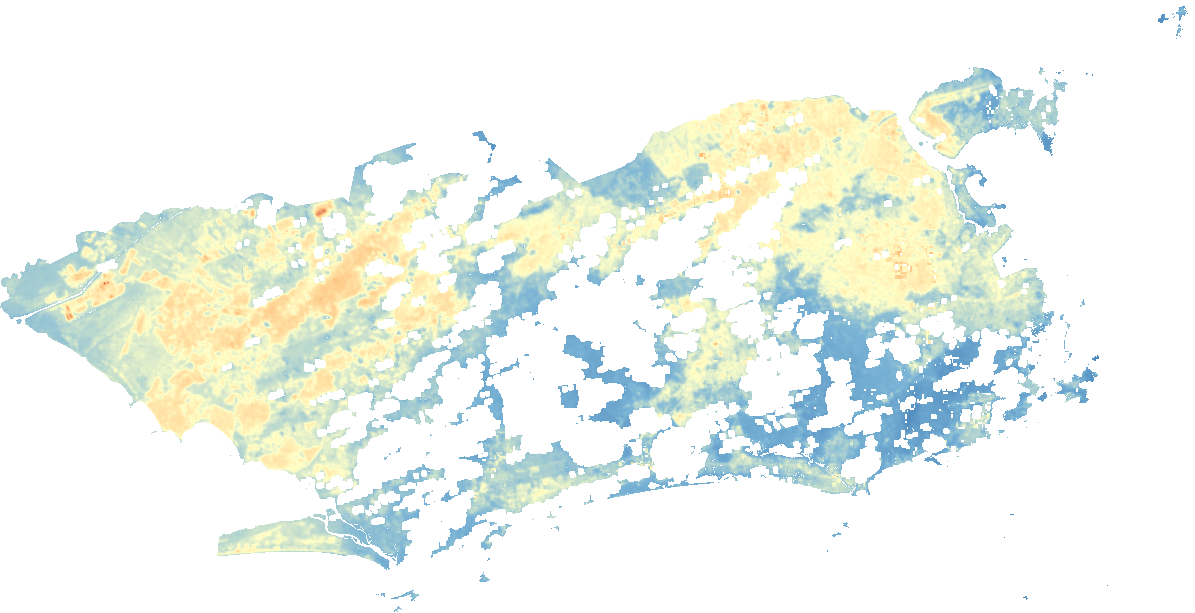

In [14]:
import rasterio
import numpy as np
import folium
import branca.colormap as cm
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds
from PIL import Image
from IPython.display import display

# Arquivo LST de 2023
arquivo = pasta / "LST_2023_RIO.tif"

with rasterio.open(arquivo) as src:
    # Reduz a resolução apenas para visualização
    escala = max(1, int(max(src.width, src.height) / 900))

    altura = max(1, src.height // escala)
    largura = max(1, src.width // escala)

    dados = src.read(
        1,
        out_shape=(altura, largura),
        resampling=Resampling.nearest,
        masked=True
    )

    limites = transform_bounds(
        src.crs, "EPSG:4326", *src.bounds
    )

valores = dados.filled(np.nan).astype(float)

# Transparência para pixels inválidos
validos = np.isfinite(valores)
validos &= (valores >= 10) & (valores <= 60)

# Escala térmica provisória
cores = cm.LinearColormap(
    ["#2166ac", "#67a9cf", "#ffffbf",
     "#fdae61", "#b2182b"],
    vmin=10,
    vmax=60
)

# Converter o raster para imagem RGBA
rgba = np.zeros((altura, largura, 4), dtype=np.uint8)

for i in range(altura):
    for j in range(largura):
        if validos[i, j]:
            cor = cores.rgba_hex_str(valores[i, j])
            rgba[i, j] = [
                int(cor[1:3], 16),
                int(cor[3:5], 16),
                int(cor[5:7], 16),
                220
            ]

# Criar mapa interativo
centro = [
    (limites[1] + limites[3]) / 2,
    (limites[0] + limites[2]) / 2
]

mapa = folium.Map(
    location=centro,
    zoom_start=10,
    tiles=None,
    zoom_control=True,
    control_scale=True
)

mapa.fit_bounds([
    [limites[1], limites[0]],
    [limites[3], limites[2]]
])

folium.raster_layers.ImageOverlay(
    image=rgba,
    bounds=[
        [limites[1], limites[0]],
        [limites[3], limites[2]]
    ],
    opacity=0.85,
    name="LST 2023"
).add_to(mapa)

cores.caption = "Temperatura de superfície (°C)"
cores.add_to(mapa)

folium.LayerControl().add_to(mapa)

display(mapa)

In [15]:
from pathlib import Path

arquivo_app = Path("/content/app.py")
codigo_atual = arquivo_app.read_text(encoding="utf-8")

marcador = "# === MAPA INTERATIVO SUHI ==="

codigo_mapa = r'''

# === MAPA INTERATIVO SUHI ===
import numpy as np
import rasterio
import folium
import branca.colormap as cm
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from streamlit_folium import st_folium
from pathlib import Path

st.divider()
st.subheader(f"Mapa de temperatura de superfície — {ano}")

@st.cache_data(show_spinner="Preparando mapa térmico...")
def preparar_mapa(ano_selecionado):
    caminho = Path(f"/content/LST_{ano_selecionado}_RIO.tif")

    with rasterio.open(caminho) as src:
        fator = max(1, int(np.ceil(max(src.width, src.height) / 1000)))
        largura = max(1, src.width // fator)
        altura = max(1, src.height // fator)

        transformacao = src.transform * src.transform.scale(
            src.width / largura, src.height / altura
        )

        origem = src.read(
            1,
            out_shape=(altura, largura),
            resampling=Resampling.nearest
        )

        destino_transform, destino_largura, destino_altura = (
            calculate_default_transform(
                src.crs, "EPSG:4326",
                largura, altura,
                *rasterio.transform.array_bounds(
                    altura, largura, transformacao
                )
            )
        )

        destino = np.full(
            (destino_altura, destino_largura),
            -9999, dtype=np.float32
        )

        reproject(
            source=origem,
            destination=destino,
            src_transform=transformacao,
            src_crs=src.crs,
            src_nodata=-9999,
            dst_transform=destino_transform,
            dst_crs="EPSG:4326",
            dst_nodata=-9999,
            resampling=Resampling.nearest
        )

    valido = (
        np.isfinite(destino)
        & (destino >= 10)
        & (destino <= 60)
    )

    paleta = np.array([
        [33, 102, 172],
        [103, 169, 207],
        [255, 255, 191],
        [253, 174, 97],
        [178, 24, 43]
    ], dtype=float)

    posicao = np.clip((destino - 10) / 50, 0, 1) * 4
    indice = np.minimum(posicao.astype(int), 3)
    fracao = (posicao - indice)[..., None]

    rgb = (
        paleta[indice] * (1 - fracao)
        + paleta[indice + 1] * fracao
    ).astype(np.uint8)

    rgba = np.zeros(
        (destino_altura, destino_largura, 4),
        dtype=np.uint8
    )
    rgba[:, :, :3] = rgb
    rgba[:, :, 3] = np.where(valido, 230, 0)

    oeste, sul, leste, norte = rasterio.transform.array_bounds(
        destino_altura, destino_largura, destino_transform
    )

    return rgba, [[sul, oeste], [norte, leste]]

try:
    imagem, limites_mapa = preparar_mapa(ano)

    centro_mapa = [
        (limites_mapa[0][0] + limites_mapa[1][0]) / 2,
        (limites_mapa[0][1] + limites_mapa[1][1]) / 2
    ]

    mapa_suhi = folium.Map(
        location=centro_mapa,
        tiles=None,
        zoom_control=True,
        control_scale=True
    )

    folium.raster_layers.ImageOverlay(
        image=imagem,
        bounds=limites_mapa,
        opacity=1,
        name=f"LST {ano}"
    ).add_to(mapa_suhi)

    escala = cm.LinearColormap(
        ["#2166ac", "#67a9cf", "#ffffbf",
         "#fdae61", "#b2182b"],
        vmin=10,
        vmax=60,
        caption="Temperatura de superfície (°C)"
    )
    escala.add_to(mapa_suhi)

    mapa_suhi.fit_bounds(limites_mapa)

    st_folium(
        mapa_suhi,
        width=None,
        height=550,
        returned_objects=[],
        key=f"mapa_{ano}"
    )

    st.caption(
        "LST Landsat 8/9 em °C. Pixels transparentes representam "
        "ausência de dados válidos. Escala fixa: 10–60 °C."
    )

except FileNotFoundError:
    st.warning(
        f"Arquivo LST_{ano}_RIO.tif não encontrado em /content."
    )
'''

if marcador not in codigo_atual:
    arquivo_app.write_text(
        codigo_atual + "\n" + codigo_mapa,
        encoding="utf-8"
    )
    print("Seção de mapas adicionada ao dashboard.")
else:
    print("A seção de mapas já existe; nenhuma duplicação foi feita.")

Seção de mapas adicionada ao dashboard.


In [16]:
import shutil

for ano_arquivo in range(2020, 2026):
    nome = f"LST_{ano_arquivo}_RIO.tif"
    shutil.copy2(pasta / nome, f"/content/{nome}")
    print("Disponível:", nome)

Disponível: LST_2020_RIO.tif
Disponível: LST_2021_RIO.tif
Disponível: LST_2022_RIO.tif
Disponível: LST_2023_RIO.tif
Disponível: LST_2024_RIO.tif
Disponível: LST_2025_RIO.tif


In [17]:
from pathlib import Path

arquivo = Path("/content/app.py")
codigo = arquivo.read_text(encoding="utf-8")

antigo = """    mapa_suhi.fit_bounds(limites_mapa)

    st_folium(
        mapa_suhi,
        width=None,
        height=550,
        returned_objects=[],
        key=f"mapa_{ano}"
    )"""

novo = """    # Ajusta automaticamente a visualização à extensão do raster
    mapa_suhi.fit_bounds(
        limites_mapa,
        padding=(25, 25)
    )

    # Exibe o mapa em uma área mais ampla
    st_folium(
        mapa_suhi,
        width=None,
        height=700,
        returned_objects=[],
        key=f"mapa_{ano}"
    )"""

if antigo in codigo:
    codigo = codigo.replace(antigo, novo)
    arquivo.write_text(codigo, encoding="utf-8")
    print("Enquadramento do mapa atualizado com sucesso.")
elif novo in codigo:
    print("O ajuste já foi aplicado anteriormente.")
else:
    print("Trecho não encontrado. Nenhuma alteração realizada.")

Enquadramento do mapa atualizado com sucesso.


In [18]:
from pathlib import Path

arquivo = Path("/content/app.py")
codigo = arquivo.read_text(encoding="utf-8")

# Amplia a largura útil do dashboard
codigo = codigo.replace(
    'layout="wide"',
    'layout="wide", initial_sidebar_state="collapsed"'
) if 'initial_sidebar_state=' not in codigo else codigo

# Ajusta o enquadramento para evitar zoom excessivo
codigo = codigo.replace(
    '''    mapa_suhi.fit_bounds(
        limites_mapa,
        padding=(25, 25)
    )''',
    '''    mapa_suhi.fit_bounds(
        limites_mapa,
        padding=(45, 45),
        max_zoom=10
    )'''
)

arquivo.write_text(codigo, encoding="utf-8")

print("Configuração de enquadramento atualizada.")

Configuração de enquadramento atualizada.


In [19]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [20]:
from pathlib import Path

arquivo = Path("/content/app.py")
codigo = arquivo.read_text(encoding="utf-8")

marcador = "# === COMPARACAO ESPACIAL SUHI ==="

nova_secao = r'''

# === COMPARACAO ESPACIAL SUHI ===

st.divider()
st.subheader("Comparação espacial entre dois anos")

st.caption(
    "Compare a distribuição espacial da temperatura de superfície "
    "em duas cenas Landsat. Os mapas utilizam a mesma escala "
    "de cores, de 10 °C a 60 °C."
)

anos_disponiveis = list(range(2020, 2026))

seletor_esquerdo, seletor_direito = st.columns(2)

with seletor_esquerdo:
    ano_esquerdo = st.selectbox(
        "Ano do primeiro mapa",
        anos_disponiveis,
        index=0,
        key="comparacao_ano_1"
    )

with seletor_direito:
    ano_direito = st.selectbox(
        "Ano do segundo mapa",
        anos_disponiveis,
        index=5,
        key="comparacao_ano_2"
    )


def construir_mapa_comparativo(ano_mapa):
    imagem, limites = preparar_mapa(ano_mapa)

    centro = [
        (limites[0][0] + limites[1][0]) / 2,
        (limites[0][1] + limites[1][1]) / 2
    ]

    mapa = folium.Map(
        location=centro,
        tiles=None,
        zoom_control=True,
        control_scale=True
    )

    folium.raster_layers.ImageOverlay(
        image=imagem,
        bounds=limites,
        opacity=1,
        name=f"LST {ano_mapa}"
    ).add_to(mapa)

    mapa.fit_bounds(
        limites,
        padding=(15, 15)
    )

    return mapa


coluna_mapa_1, coluna_mapa_2 = st.columns(2)

with coluna_mapa_1:
    st.markdown(f"**LST — {ano_esquerdo}**")

    try:
        mapa_1 = construir_mapa_comparativo(ano_esquerdo)

        st_folium(
            mapa_1,
            width=None,
            height=450,
            returned_objects=[],
            key=f"comparacao_mapa_1_{ano_esquerdo}"
        )

    except FileNotFoundError:
        st.warning(
            f"Raster LST_{ano_esquerdo}_RIO.tif não encontrado."
        )

with coluna_mapa_2:
    st.markdown(f"**LST — {ano_direito}**")

    try:
        mapa_2 = construir_mapa_comparativo(ano_direito)

        st_folium(
            mapa_2,
            width=None,
            height=450,
            returned_objects=[],
            key=f"comparacao_mapa_2_{ano_direito}"
        )

    except FileNotFoundError:
        st.warning(
            f"Raster LST_{ano_direito}_RIO.tif não encontrado."
        )


# Escala térmica compartilhada
escala_comparacao = cm.LinearColormap(
    [
        "#2166ac",
        "#67a9cf",
        "#ffffbf",
        "#fdae61",
        "#b2182b"
    ],
    vmin=10,
    vmax=60
)

st.markdown("**Escala térmica compartilhada (°C)**")

st.image(
    "data:image/svg+xml;base64," +
    __import__("base64").b64encode(
        (
            '<svg xmlns="http://www.w3.org/2000/svg" '
            'width="700" height="55">'
            '<defs><linearGradient id="g">'
            '<stop offset="0%" stop-color="#2166ac"/>'
            '<stop offset="25%" stop-color="#67a9cf"/>'
            '<stop offset="50%" stop-color="#ffffbf"/>'
            '<stop offset="75%" stop-color="#fdae61"/>'
            '<stop offset="100%" stop-color="#b2182b"/>'
            '</linearGradient></defs>'
            '<rect x="20" y="5" width="660" height="20" '
            'fill="url(#g)"/>'
            '<g font-size="14" fill="#333">'
            '<text x="20" y="45">10</text>'
            '<text x="180" y="45">23</text>'
            '<text x="345" y="45">35</text>'
            '<text x="510" y="45">48</text>'
            '<text x="655" y="45">60 °C</text>'
            '</g></svg>'
        ).encode("utf-8")
    ).decode("ascii"),
    use_container_width=True
)

st.info(
    "Comparação visual exploratória: as cenas Landsat "
    "foram adquiridas em datas diferentes e apresentam "
    "coberturas distintas de pixels válidos. "
    "Diferenças de cor não representam, isoladamente, "
    "mudanças comprovadas na intensidade das ilhas de calor."
)
'''

if marcador not in codigo:
    arquivo.write_text(
        codigo + "\n" + nova_secao,
        encoding="utf-8"
    )
    print("Comparação espacial adicionada com sucesso!")
else:
    print("A comparação espacial já existe no app.py.")

Comparação espacial adicionada com sucesso!


In [21]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [22]:
from google.colab import files

files.download("/content/app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from google.colab import files

files.download("/content/estatisticas_SUHI_2020_2025.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>